# 🌾 Buğday Tohumu Türü Sınıflandırma (Wheat Seeds Multi-Class Classification)
**PyTorch Derin Öğrenme Eğitimi - Bağımsız Uygulama Laboratuvarı**

Bu çalışmada, yüksek çözünürlüklü röntgen teknikleriyle elde edilmiş geometrik morfoloji ölçümlerini kullanarak **3 farklı buğday tohumu türünü (*Kama, Rosa, Canadian*)** sınıflandıran çok katmanlı yapay sinir ağı (MLP) mimarisi kurulmuş ve eğitilmiştir.

### 📋 Proje Adımları:
1. **Keşifsel Veri Analizi (EDA):** Veri dağılımı, eksik değer kontrolü ve geometrik özelliklerin incelenmesi.
2. **Özellik ($X$) ve Hedef ($y$) Ayrımı:** Hedef sınıfların sıfır tabanlı indeksleme için `LabelEncoder` ile hazırlanması.
3. **Train / Test Ayrımı (`stratify=y`):** Sınıf dengesinin korunması.
4. **Özellik Ölçeklendirme (`StandardScaler`):** Geometrik alan ve çevre değerlerinin standart normal dağılıma çekilmesi.
5. **PyTorch Tenzör Dönüşümü:** `float32` girdi ve `long` hedef veri tipleri.
6. **Yapay Sinir Ağı Mimarisi:** Parametrik `nn.Module` (7 Girdi $ightarrow$ 16 Gizli $ightarrow$ 16 Gizli $ightarrow$ 3 Çıktı).
7. **Eğitim Döngüsü & Overfitting Analizi:** Loss ve Accuracy eğrilerinin takibi ve aşırı öğrenme incelemesi.
8. **Confusion Matrix (Karmaşıklık Matrisi):** Modelin hangi tohumları karıştırdığının tespiti.
9. **Model Kaydı (`.pth`) & Çıkarım (Inference):** Ağırlıkların kaydedilmesi ve yeni tohum tahmini.

## 1. Gerekli Kütüphanelerin Yüklenmesi

In [1]:
import torch
from torch import nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Modern görsel tema
sns.set_theme(style="whitegrid")
print(f"PyTorch Versiyonu: {torch.__version__}")

PyTorch Versiyonu: 2.14.0


## 2. Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)

In [2]:
df = pd.read_csv("wheat_seeds.csv")
df.head()

,area,perimeter,compactness,length_of_kernel,width_of_kernel,asymmetry_coefficient,length_of_groove,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [3]:
# Veri tipleri ve bellek kullanımı
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   area                   210 non-null    float64
 1   perimeter              210 non-null    float64
 2   compactness            210 non-null    float64
 3   length_of_kernel       210 non-null    float64
 4   width_of_kernel        210 non-null    float64
 5   asymmetry_coefficient  210 non-null    float64
 6   length_of_groove       210 non-null    float64
 7   variety                210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


In [4]:
# Sayısal özelliklerin istatistiksel dağılımı
df.describe().T

,count,mean,std,min,25%,50%,75%,max
area,210.0,14.847524,2.909699,10.5900,12.27000,14.35500,17.305000,21.1800
perimeter,210.0,14.559286,1.305959,12.4100,13.45000,14.32000,15.715000,17.2500
compactness,210.0,0.870999,0.023629,0.8081,0.85690,0.87345,0.887775,0.9183
length_of_kernel,210.0,5.628533,0.443063,4.8990,5.26225,5.52350,5.979750,6.6750
width_of_kernel,210.0,3.258605,0.377714,2.6300,2.94400,3.23700,3.561750,4.0330
asymmetry_coefficient,210.0,3.700201,1.503557,0.7651,2.56150,3.59900,4.768750,8.4560
length_of_groove,210.0,5.408071,0.491480,4.5190,5.04500,5.22300,5.877000,6.5500
variety,210.0,2.000000,0.818448,1.0000,1.00000,2.00000,3.000000,3.0000


In [5]:
# Sınıf dağılımı (Her sınıftan tam 70'er adet - Mükemmel dengeli veri seti)
df["variety"].value_counts()

variety
1    70
2    70
3    70
Name: count, dtype: int64

In [6]:
# Eksik veri kontrolü (Tek bir eksik değer dahi yok!)
df.isnull().sum()

area                     0
perimeter                0
compactness              0
length_of_kernel         0
width_of_kernel          0
asymmetry_coefficient    0
length_of_groove         0
variety                  0
dtype: int64

### 📊 Veri Dağılımı: Tohum Alanı vs Çevre Uzunluğu
Buğday tohumlarının alan (`area`) ve çevre (`perimeter`) ölçümlerine göre türlerin nasıl ayrıştığına bakalım:

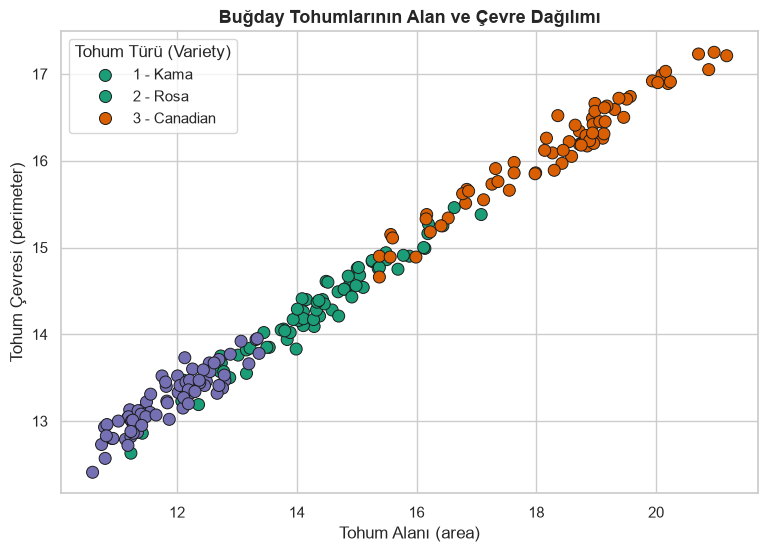

In [7]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="area",
    y="perimeter",
    hue="variety",
    palette="Dark2",
    s=75,
    edgecolor="k"
)
plt.title("Buğday Tohumlarının Alan ve Çevre Dağılımı", fontsize=13, weight="bold")
plt.xlabel("Tohum Alanı (area)")
plt.ylabel("Tohum Çevresi (perimeter)")
plt.legend(title="Tohum Türü (Variety)", labels=["1 - Kama", "2 - Rosa", "3 - Canadian"])
plt.show()

## 3. Özellik ($X$) - Hedef ($y$) Ayrımı & Label Encoding

* **Girdi Özellikleri ($X$):** 7 adet geometrik ölçüm (`area`, `perimeter`, `compactness`, `length_of_kernel`, `width_of_kernel`, `asymmetry_coefficient`, `length_of_groove`).
* **Hedef ($y$):** `variety` sütunu. Orijinal veride `1, 2, 3` olarak verildiği için PyTorch'un sıfır tabanlı indeksleme standardına uygun olarak `LabelEncoder` ile `[0, 1, 2]` formatına dönüştürülür.

In [8]:
# Girdi matrisi (7 sütun)
X = df.drop("variety", axis=1).values

# Hedef vektör (0, 1, 2 indeksleri)
le = LabelEncoder()
y = le.fit_transform(df["variety"])

print(f"X Boyutu: {X.shape} (210 örnek, 7 özellik)")
print(f"y Boyutu: {y.shape}")
print(f"Orijinal Sınıflar: {le.classes_} -> Kodlanan İndeksler: [0, 1, 2]")

X Boyutu: (210, 7) (210 örnek, 7 özellik)
y Boyutu: (210,)
Orijinal Sınıflar: [1 2 3] -> Kodlanan İndeksler: [0, 1, 2]


## 4. Train / Test Ayrımı (`stratify=y`) & `StandardScaler`

Veriyi %80 Eğitim (Train) ve %20 Test olarak ayırıyoruz. `stratify=y` ile her sınıftan eşit oranda (56 eğitim, 14 test) bölünmesini garanti ediyoruz.
Ardından `StandardScaler` uygulayarak özellikleri sıfır ortalama ve birim varyansa getiriyoruz.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Sadece X_train fit edilir (Data Leakage engellenir!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Eğitim Kümesi: {X_train_scaled.shape}")
print(f"Test Kümesi  : {X_test_scaled.shape}")

Eğitim Kümesi: (168, 7)
Test Kümesi  : (42, 7)


## 5. PyTorch Tenzör Dönüşümü

* $X$ (Girdiler) $ightarrow$ `torch.float32`
* $y$ (Etiketler) $ightarrow$ `torch.long` (1 boyutlu `(N,)` tenzör)

In [10]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("X_train Tipi & Boyutu:", X_train_tensor.dtype, X_train_tensor.shape)
print("y_train Tipi & Boyutu:", y_train_tensor.dtype, y_train_tensor.shape)

X_train Tipi & Boyutu: torch.float32 torch.Size([168, 7])
y_train Tipi & Boyutu: torch.int64 torch.Size([168])


## 6. Çok Katmanlı Yapay Sinir Ağı Mimarisi (`nn.Module`)

Esnek ve modüler bir mimari için katman boyutlarını parametrik tanımlıyoruz:

In [11]:
class WheatSeedsClassifier(nn.Module):
    """
    Buğday Tohumu Sınıflandırma Yapay Sinir Ağı Mimarisi (MLP)
    """
    def __init__(self, in_features: int = 7, out_features: int = 3, hidden_units: int = 16):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Linear(in_features=in_features, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=out_features)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layer_stack(x)

# Modelin başlatılması
torch.manual_seed(42)
model = WheatSeedsClassifier(in_features=7, out_features=3, hidden_units=16)
print(model)

WheatSeedsClassifier(
  (layer_stack): Sequential(
    (0): Linear(in_features=7, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=3, bias=True)
  )
)


## 7. Kayıp Fonksiyonu, Optimizer ve Metrik Tanımı

In [12]:
# Kayıp Fonksiyonu (Ham lojitler için)
loss_fn = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.01)

# Doğruluk Metriği
def calculate_accuracy(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return (correct / len(y_pred)) * 100

## 8. Model Eğitimi (Training Loop - 100 Epoch)

In [13]:
torch.manual_seed(42)
epochs = 100

epoch_count = []
train_loss_values = []
test_loss_values = []
train_acc_values = []
test_acc_values = []

for epoch in range(epochs):
    ### --- 1. EĞİTİM (TRAINING) ---
    model.train()
    
    # 1. Forward Pass
    y_logits = model(X_train_tensor)
    y_pred = y_logits.argmax(dim=1)
    
    # 2. Loss & Accuracy
    loss = loss_fn(y_logits, y_train_tensor)
    acc = calculate_accuracy(y_train_tensor, y_pred)
    
    # 3. Gradyan Sıfırlama
    optimizer.zero_grad()
    
    # 4. Backpropagation
    loss.backward()
    
    # 5. Gradient Descent (Adım)
    optimizer.step()
    
    ### --- 2. DEĞERLENDİRME (TESTING) ---
    model.eval()
    with torch.inference_mode():
        test_logits = model(X_test_tensor)
        test_pred = test_logits.argmax(dim=1)
        
        test_loss = loss_fn(test_logits, y_test_tensor)
        test_acc = calculate_accuracy(y_test_tensor, test_pred)
        
    epoch_count.append(epoch)
    train_loss_values.append(loss.item())
    test_loss_values.append(test_loss.item())
    train_acc_values.append(acc)
    test_acc_values.append(test_acc)
    
    if epoch % 10 == 0:
        print(f"Epoch: {epoch:3d} | Train Loss: {loss:.4f}, Train Acc: %{acc:.2f} | Test Loss: {test_loss:.4f}, Test Acc: %{test_acc:.2f}")

print(f"\nEğitim Tamamlandı! Final Test Doğruluğu: %{test_acc_values[-1]:.2f}")

Epoch:   0 | Train Loss: 1.0910, Train Acc: %33.33 | Test Loss: 1.0599, Test Acc: %38.10
Epoch:  10 | Train Loss: 0.6421, Train Acc: %85.12 | Test Loss: 0.6685, Test Acc: %76.19
Epoch:  20 | Train Loss: 0.3081, Train Acc: %89.88 | Test Loss: 0.3339, Test Acc: %85.71
Epoch:  30 | Train Loss: 0.1891, Train Acc: %92.26 | Test Loss: 0.2645, Test Acc: %85.71
Epoch:  40 | Train Loss: 0.1351, Train Acc: %93.45 | Test Loss: 0.3114, Test Acc: %85.71
Epoch:  50 | Train Loss: 0.1005, Train Acc: %95.24 | Test Loss: 0.4587, Test Acc: %85.71
Epoch:  60 | Train Loss: 0.0830, Train Acc: %95.83 | Test Loss: 0.5015, Test Acc: %83.33
Epoch:  70 | Train Loss: 0.0653, Train Acc: %96.43 | Test Loss: 0.5258, Test Acc: %83.33
Epoch:  80 | Train Loss: 0.0500, Train Acc: %98.81 | Test Loss: 0.5663, Test Acc: %85.71
Epoch:  90 | Train Loss: 0.0362, Train Acc: %99.40 | Test Loss: 0.6312, Test Acc: %85.71

Eğitim Tamamlandı! Final Test Doğruluğu: %85.71


### 📈 Öğrenme Eğrileri & Overfitting (Aşırı Öğrenme) İncelemesi

> [!IMPORTANT]
> **Vaka Analizi (Overfitting Tespiti):**
> * Grafiklere dikkat edildiğinde, **Epoch 30 civarında** Test Kaybı (Test Loss) en düşük seviyesine (`0.2645`) inmiş ve Test Doğruluğu `%85.71` seviyesine ulaşmıştır.
> * Ancak 30. epoch'tan sonra model eğitim verisini ezberlemeye başladığı için Train Loss sıfıra yaklaşırken (`0.0362`), **Test Loss yukarı tırmanmaya başlamıştır (`0.6312`)**. 
> * Bu durum, derin öğrenmede ideal durdurma noktasını (**Early Stopping**) gösteren mükemmel bir ders örneğidir.

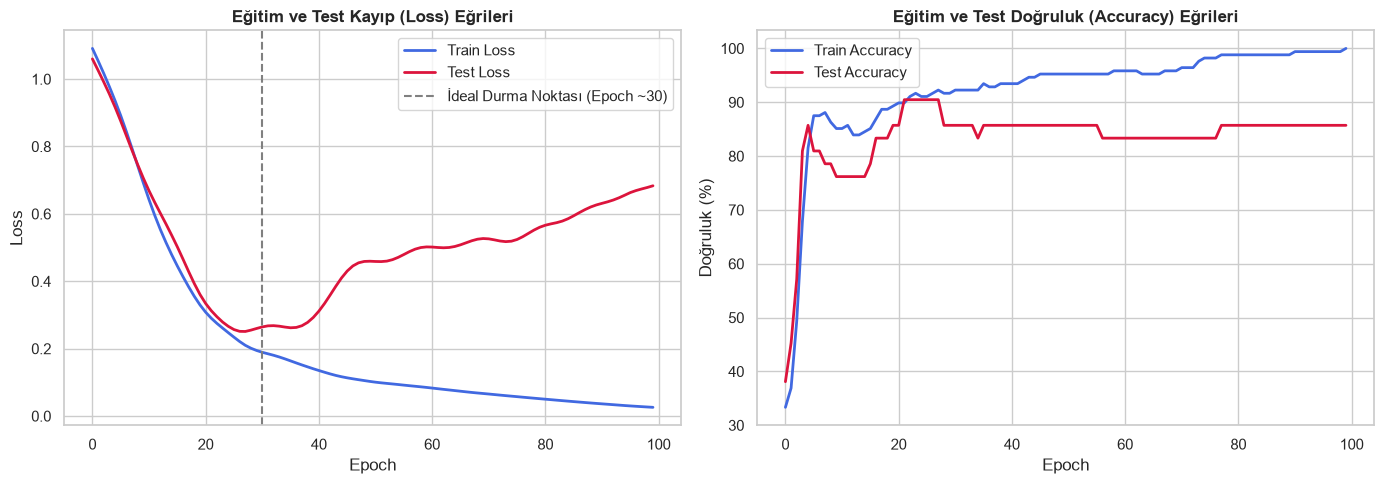

In [14]:
plt.figure(figsize=(14, 5))

# Loss Eğrisi
plt.subplot(1, 2, 1)
plt.plot(epoch_count, train_loss_values, label="Train Loss", color="royalblue", lw=2)
plt.plot(epoch_count, test_loss_values, label="Test Loss", color="crimson", lw=2)
plt.axvline(x=30, color="gray", linestyle="--", label="İdeal Durma Noktası (Epoch ~30)")
plt.title("Eğitim ve Test Kayıp (Loss) Eğrileri", fontsize=12, weight="bold")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# Accuracy Eğrisi
plt.subplot(1, 2, 2)
plt.plot(epoch_count, train_acc_values, label="Train Accuracy", color="royalblue", lw=2)
plt.plot(epoch_count, test_acc_values, label="Test Accuracy", color="crimson", lw=2)
plt.title("Eğitim ve Test Doğruluk (Accuracy) Eğrileri", fontsize=12, weight="bold")
plt.xlabel("Epoch")
plt.ylabel("Doğruluk (%)")
plt.legend()

plt.tight_layout()
plt.show()

## 9. Performans Değerlendirmesi: Confusion Matrix (Karmaşıklık Matrisi)

Test kümesindeki 42 örneğin türlere göre dağılımını inceleyelim:

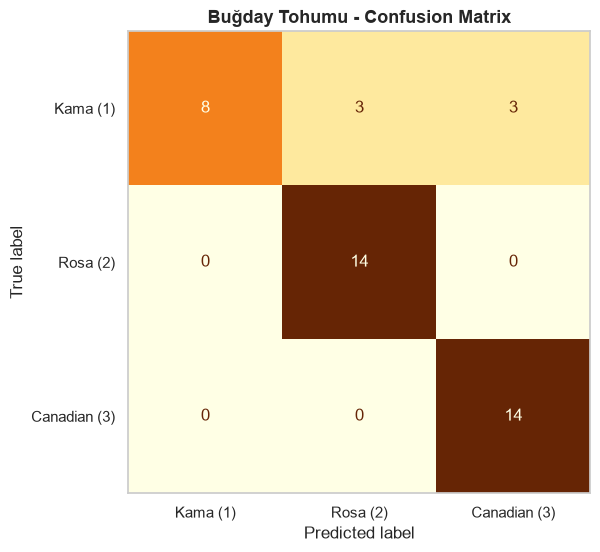

In [15]:
model.eval()
with torch.inference_mode():
    final_test_logits = model(X_test_tensor)
    final_test_preds = final_test_logits.argmax(dim=1)

cm = confusion_matrix(y_test_tensor.numpy(), final_test_preds.numpy())
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Kama (1)", "Rosa (2)", "Canadian (3)"])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="YlOrBr", values_format="d", ax=ax, colorbar=False)
plt.title("Buğday Tohumu - Confusion Matrix", fontsize=13, weight="bold")
plt.grid(False)
plt.show()

## 10. Modelin Diske Kaydedilmesi (`.pth`) & Canlı Çıkarım (Inference)

In [16]:
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "wheat_seeds_model.pth"
MODEL_SAVE_PATH = MODEL_DIR / MODEL_NAME

torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f"Model başarıyla kaydedildi: {MODEL_SAVE_PATH}")

Model başarıyla kaydedildi: models/wheat_seeds_model.pth


### 🔮 Canlı Test: Yeni Bir Buğday Tohumu ile Tahmin

In [17]:
# Yeni tohum ölçümü [area=14.5, perimeter=14.2, compactness=0.88, len_k=5.5, wid_k=3.2, asym=3.1, len_g=5.1]
yeni_tohum = np.array([[14.5, 14.2, 0.88, 5.5, 3.2, 3.1, 5.1]])

# Eğitimdeki scaler ile normalize ediyoruz! (Sadece transform!)
yeni_tohum_scaled = scaler.transform(yeni_tohum)
yeni_tohum_tensor = torch.tensor(yeni_tohum_scaled, dtype=torch.float32)

model.eval()
with torch.inference_mode():
    logits = model(yeni_tohum_tensor)
    probs = torch.softmax(logits, dim=1)[0]
    tahmin_idx = torch.argmax(probs).item()

tur_isimleri = ["Kama (Tür 1)", "Rosa (Tür 2)", "Canadian (Tür 3)"]
print(f"Tahmin Edilen Buğday Türü: {tur_isimleri[tahmin_idx]}")
print(f"Güven Oranı (Confidence): %{probs[tahmin_idx].item() * 100:.2f}")
print("\nOlasılık Dağılımı:")
for i, tur in enumerate(tur_isimleri):
    print(f"  {tur:20s}: %{probs[i].item() * 100:.2f}")

Tahmin Edilen Buğday Türü: Kama (Tür 1)
Güven Oranı (Confidence): %99.96

Olasılık Dağılımı:
  Kama (Tür 1)        : %99.96
  Rosa (Tür 2)        : %0.00
  Canadian (Tür 3)    : %0.03


## 📝 Modül Özeti & Önemli Çıkarımlar

1. **Sıfır Tabanlı İndeksleme:** Hedef etiketleri `1, 2, 3` olduğunda PyTorch `IndexError` vermesin diye `LabelEncoder` ile `0, 1, 2` yapılmıştır.
2. **Ölçeklendirme:** Geometrik özellikler `StandardScaler` ile normalize edilmiştir.
3. **Overfitting Gözlemi:** Model Epoch 30'da optimal noktasına ulaşmış, sonrasında eğitim verisini ezberlemeye yönelmiştir (Early Stopping gereksinimi).
4. **Başarı:** Test kümesinde **%85.71 doğruluk** elde edilmiş ve ağırlıklar `.pth` olarak kaydedilmiştir.

---
*Geliştirici: Tunahan Bucak | PyTorch & Deep Learning Mastery*